In [2]:
import lightgbm as lgb
print('lightgbm', lgb.__version__)

lightgbm 4.7.0


In [3]:
import sys
import pandas as pd
import lightgbm as lgb

sys.path.insert(0, '..')              # notebooks/ -> repo root, so src is importable
from src.columns import NON_FEATURES

print("lightgbm", lgb.__version__)


# ---- 1. load ------------------------------------------------------------
train = pd.read_parquet('../data/processed/features_train.parquet')
test  = pd.read_parquet('../data/processed/features_test.parquet')

# features.py writes these in time order, but a new notebook does not get
# to assume it - and TimeSeriesSplit cuts by row position
assert train['issue_d'].is_monotonic_increasing, "train is not in time order"
assert test['issue_d'].is_monotonic_increasing,  "test is not in time order"

print("train:", train.shape, train['issue_d'].min().date(), "->", train['issue_d'].max().date())
print("test: ", test.shape,  test['issue_d'].min().date(),  "->", test['issue_d'].max().date())


# ---- 2. the same split as slice 5, by date not by row position ----------
SPLIT_DATE = pd.Timestamp('2016-01-01')

train_inner = train[train['issue_d'] <  SPLIT_DATE].copy()
valid       = train[train['issue_d'] >= SPLIT_DATE].copy()


# ---- 3. prove the ground is identical to slice 5 ------------------------
assert len(train_inner) + len(valid) == len(train),           "rows lost or duplicated"
assert train_inner['issue_d'].max() < valid['issue_d'].min(), "the sets overlap in time"
assert train_inner['issue_d'].is_monotonic_increasing
assert valid['issue_d'].is_monotonic_increasing

expected = [("train_inner", train_inner, 16134, 0.1890),
            ("valid",       valid,        4768, 0.2391),
            ("test",        test,         5378, 0.2365)]

for name, df, n_rows, bad_rate in expected:
    assert len(df) == n_rows, f"{name} has {len(df)} rows, slice 5 had {n_rows}"
    assert abs(df['target'].mean() - bad_rate) < 1e-4, \
        f"{name} bad rate {df['target'].mean():.4f}, slice 5 had {bad_rate}"

print(pd.DataFrame([
    {"set": name, "rows": len(df),
     "from": df['issue_d'].min().date(), "to": df['issue_d'].max().date(),
     "bad_rate": df['target'].mean()}
    for name, df, _, _ in expected
]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))


# ---- 4. X and y - no scaler, trees split on thresholds ------------------
X_train_inner = train_inner.drop(columns=NON_FEATURES)
y_train_inner = train_inner['target']

X_valid = valid.drop(columns=NON_FEATURES)
y_valid = valid['target']

X_test  = test.drop(columns=NON_FEATURES)
y_test  = test['target']

assert list(X_train_inner.columns) == list(X_valid.columns), "valid columns differ"
assert list(X_train_inner.columns) == list(X_test.columns),  "test columns differ"
assert X_train_inner.shape[1] == 71, f"expected 71 features, got {X_train_inner.shape[1]}"

print("\ntrain_inner:", X_train_inner.shape)
print("valid:      ", X_valid.shape)
print("test:       ", X_test.shape)

lightgbm 4.7.0
train: (20902, 76) 2013-01-01 -> 2016-08-01
test:  (5378, 76) 2016-09-01 -> 2017-12-01
        set  rows       from         to  bad_rate
train_inner 16134 2013-01-01 2015-12-01    0.1890
      valid  4768 2016-01-01 2016-08-01    0.2391
       test  5378 2016-09-01 2017-12-01    0.2365

train_inner: (16134, 71)
valid:       (4768, 71)
test:        (5378, 71)


In [4]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier


# ---- 1. the harness -----------------------------------------------------
tscv = TimeSeriesSplit(n_splits=5)

for i, (tr, te) in enumerate(tscv.split(X_train_inner), 1):
    d_tr = train_inner['issue_d'].iloc[tr]
    d_te = train_inner['issue_d'].iloc[te]
    print(f"fold {i}:  train {len(tr):>5} rows  {d_tr.min().date()} -> {d_tr.max().date()}"
          f"   |  score {len(te):>5} rows  {d_te.min().date()} -> {d_te.max().date()}")


# ---- 2. the logistic reference: slice 5's model, re-measured on folds ----
# the scaler must be refitted inside each fold, or it learns from the rows
# that fold is about to be scored on. the Pipeline is what makes that happen.
pipe_logreg = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(C=0.05, l1_ratio=1.0, solver='liblinear',
                                  max_iter=2000, random_state=42)),
])


# ---- 3. the boosted model, pure defaults --------------------------------
lgbm = LGBMClassifier(
    objective='binary',
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

params = lgbm.get_params()
print(f"\ndefaults: num_leaves={params['num_leaves']}  "
      f"learning_rate={params['learning_rate']}  "
      f"n_estimators={params['n_estimators']}")


# ---- 4. both models, identical folds ------------------------------------
scores_logreg = cross_val_score(pipe_logreg, X_train_inner, y_train_inner,
                                cv=tscv, scoring='roc_auc')
scores_lgb    = cross_val_score(lgbm, X_train_inner, y_train_inner,
                                cv=tscv, scoring='roc_auc')

diff = scores_lgb - scores_logreg

print(f"\nlogreg   mean {scores_logreg.mean():.4f}   std {scores_logreg.std():.4f}")
print(f"lightgbm mean {scores_lgb.mean():.4f}   std {scores_lgb.std():.4f}")
print()
print("per fold logreg  :", np.round(scores_logreg, 4))
print("per fold lightgbm:", np.round(scores_lgb, 4))
print("per fold diff    :", np.round(diff, 4))
print()
print(f"mean difference:       {diff.mean():+.4f}")
print(f"folds won by lightgbm: {(diff > 0).sum()} of {len(diff)}")


# ---- 5. the overfit gap -------------------------------------------------
# NOTE: this fits lgbm IN PLACE. from here on, lgbm is a model that has seen
# all of train_inner. cross_val_score clones before each fold so it is
# unaffected - but any direct .predict() after this saw everything.
lgbm.fit(X_train_inner, y_train_inner)

p_in_sample   = lgbm.predict_proba(X_train_inner)[:, 1]
auc_in_sample = roc_auc_score(y_train_inner, p_in_sample)

print(f"\nin-sample AUC (rows it trained on): {auc_in_sample:.4f}")
print(f"CV mean AUC   (rows it never saw):  {scores_lgb.mean():.4f}")
print(f"gap:                                {auc_in_sample - scores_lgb.mean():.4f}")

fold 1:  train  2689 rows  2013-01-01 -> 2013-12-01   |  score  2689 rows  2013-12-01 -> 2014-07-01
fold 2:  train  5378 rows  2013-01-01 -> 2014-07-01   |  score  2689 rows  2014-07-01 -> 2015-01-01
fold 3:  train  8067 rows  2013-01-01 -> 2015-01-01   |  score  2689 rows  2015-01-01 -> 2015-05-01
fold 4:  train 10756 rows  2013-01-01 -> 2015-05-01   |  score  2689 rows  2015-05-01 -> 2015-09-01
fold 5:  train 13445 rows  2013-01-01 -> 2015-09-01   |  score  2689 rows  2015-09-01 -> 2015-12-01

defaults: num_leaves=31  learning_rate=0.1  n_estimators=100

logreg   mean 0.7107   std 0.0128
lightgbm mean 0.6830   std 0.0191

per fold logreg  : [0.6999 0.6913 0.7189 0.7192 0.7243]
per fold lightgbm: [0.6554 0.6667 0.6906 0.6951 0.7073]
per fold diff    : [-0.0446 -0.0246 -0.0283 -0.024  -0.017 ]

mean difference:       -0.0277
folds won by lightgbm: 0 of 5

in-sample AUC (rows it trained on): 0.9304
CV mean AUC   (rows it never saw):  0.6830
gap:                                0.2474


In [5]:
import joblib

# ---- 1. how far outside is 19.5? ----------------------------------------
lti_max = X_train_inner['loan_to_income'].max()

print(f"loan_to_income training max: {lti_max:.3f}")
print(f"19.5 is {19.5 / lti_max:.1f}x beyond anything in training")


# ---- 2. an ordinary base row --------------------------------------------
lti_median = X_train_inner['loan_to_income'].median()
base_idx   = (X_train_inner['loan_to_income'] - lti_median).abs().idxmin()

# .loc not .iloc - idxmin gives an index LABEL, and train_inner kept its
# original labels from train (step 1 used a boolean mask, no reset_index)
base_row = X_train_inner.loc[[base_idx]].copy()

print(f"\nloan_to_income median: {lti_median:.3f}")
print(f"base row label:        {base_idx}")
print(f"base row value:        {base_row['loan_to_income'].iloc[0]:.3f}")
print(f"base row shape:        {base_row.shape}")

check = ['fico', 'dti', 'revol_util', 'credit_history_months']
print()
print(pd.DataFrame({'base row':     base_row[check].iloc[0],
                    'train median': X_train_inner[check].median()}))


# ---- 3. the same borrower, one number changed ---------------------------
extreme_row = base_row.copy()          # without .copy() BOTH rows get 19.5
extreme_row.loc[:, 'loan_to_income'] = 19.5

both = pd.concat([base_row, extreme_row]).reset_index(drop=True)

assert both.shape == (2, 71)
assert both['loan_to_income'].nunique() == 2, "both rows have the same value"
assert (both.drop(columns='loan_to_income').nunique() == 1).all(), \
    "the rows differ in more than loan_to_income"


# ---- 4. the tree model --------------------------------------------------
p_lgb = lgbm.predict_proba(both)[:, 1]


# ---- 5. the slice 5 bundle ----------------------------------------------
bundle = joblib.load('../models/calibrated_logreg.joblib')
print("\napply order:", bundle['apply_order'])

assert bundle['loan_to_income_guard_not_applied'] == lti_max, \
    "this train_inner is not slice 5's train_inner"

X        = both[bundle['columns']]              # the scaler works by POSITION
X_scaled = pd.DataFrame(bundle['scaler'].transform(X),
                        columns=bundle['columns'], index=X.index)
score    = bundle['model'].decision_function(X_scaled)
p_log    = bundle['calibrator'].predict_proba(score.reshape(-1, 1))[:, 1]


# ---- 6. the table -------------------------------------------------------
print(f"\nbase loan_to_income {base_row['loan_to_income'].iloc[0]:.3f}"
      f"  ->  changed to 19.500\n")

print(pd.DataFrame([
    {"model": "logistic (slice 5)", "normal": p_log[0],
     "at 19.5": p_log[1], "change": p_log[1] - p_log[0]},
    {"model": "lightgbm (default)", "normal": p_lgb[0],
     "at 19.5": p_lgb[1], "change": p_lgb[1] - p_lgb[0]},
]).to_string(index=False, float_format=lambda v: f"{v:.6f}"))

print(f"\nraw log-odds: {score[0]:+.3f}  ->  {score[1]:+.3f}")

loan_to_income training max: 1.782
19.5 is 10.9x beyond anything in training

loan_to_income median: 0.207
base row label:        4514
base row value:        0.207
base row shape:        (1, 71)

                       base row  train median
fico                     697.00        687.00
dti                       10.52         17.88
revol_util                77.00         55.50
credit_history_months    249.00        181.00

apply order: ['scaler.transform', 'model.decision_function', 'calibrator.predict_proba[:, 1]']

base loan_to_income 0.207  ->  changed to 19.500

             model   normal  at 19.5   change
logistic (slice 5) 0.077021 1.000000 0.922979
lightgbm (default) 0.045647 0.254413 0.208767

raw log-odds: -2.927  ->  +31.604


## Step 4 — tuning search, declared 2026-11-16

Declared before any tuning run. Not edited afterwards.

### Why we are searching
The default LightGBM lost to the slice 5 logistic model on all five folds
(0.6830 vs 0.7107, mean paired difference -0.0277). In-sample 0.9304 against
CV 0.6830 — a gap of 0.2474. The model memorises. The search cuts complexity.

### Fixed, not searched
objective='binary', random_state=42, n_jobs=-1, verbose=-1.
n_estimators=2000 as a ceiling only; early stopping decides the real count.
early stopping: 50 rounds, metric 'auc', watching the last 20% of each fold's
training rows, split by position so it stays latest in time.
No class weighting (is_unbalance / scale_pos_weight): it inflates every
probability and step 5 is calibration.

### The grid — 4 x 4 x 2 = 32 combinations, 160 fits
| parameter          | values              | default |
|--------------------|---------------------|---------|
| num_leaves         | 4, 8, 16, 31        | 31      |
| min_child_samples  | 20, 50, 100, 200    | 20      |
| learning_rate      | 0.02, 0.05          | 0.1     |

The defaults are inside the grid on purpose, so the known reference point is
part of the search rather than outside it.

### Stopping rule
All 32 combinations run. The loop does not stop early for any reason,
including a combination beating 0.7107.

### Selection rule
Highest mean fold AUC. If several sit within one fold-to-fold standard
deviation of the best, take the SIMPLEST of those - fewest num_leaves first,
then largest min_child_samples. Same rule slice 4 used to pick C=0.05 over
C=0.1 when they were 0.0002 apart.

### Win condition
Measured as a paired per-fold difference against scores_logreg, not as a
comparison of two means:
  - positive in all 5 folds, OR
  - positive in 4 of 5 AND mean difference larger than the standard
    deviation of the differences.
A higher mean AUC alone is NOT a win.

### Edge rule
If the selected combination sits on an edge of the grid (num_leaves=4,
min_child_samples=200, or learning_rate=0.02), the grid was too narrow.
That permits ONE extended search, declared in a new dated cell before running.

### The lose case
If nothing meets the win condition, the slice 5 calibrated logistic model
ships as the slice 6 model. Boosting is reported as tried, tuned and beaten.
Slices 7-10 proceed with logistic. This was committed in writing in
docs/slice_04_baseline_model.md before slice 6 began.

### Known caveat
The winner's CV AUC is the maximum of 32 noisy values, so it is optimistic.
CV is the selection device here, not the result. The honest number is the
test AUC at step 6, measured once.

## Step 4 — extended search, declared 2026-11-16 (amendment)

The first search selected num_leaves=4, min_child_samples=200,
learning_rate=0.02 — all three on a grid edge. The edge rule in the original
declaration permits ONE extended search, declared before running. This is it.
No further extension is permitted.

### The extended grid — 2 x 3 x 2 = 12 combinations
| parameter          | values          | first search  |
|--------------------|-----------------|---------------|
| num_leaves         | 2, 3            | 4, 8, 16, 31  |
| min_child_samples  | 200, 400, 800   | 20 ... 200    |
| learning_rate      | 0.01, 0.02      | 0.02, 0.05    |

num_leaves=2 is a decision stump — one split per tree, so no interactions at
all. If that wins, the signal in this data is additive.

### Everything else unchanged
Same FIXED, same folds, same early stopping, same selection rule, same win
condition, same lose case as the declaration above.

### If the winner is again on an edge
Stop. The extension is spent. Report the result as it stands, with the edge
recorded as a limitation.

In [5]:
# ============ CELL 2: the harness ============
import numpy as np
import pandas as pd
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from itertools import product

FIXED = dict(
    objective='binary',
    n_estimators=2000,        # ceiling only - early stopping picks the real number
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

WATCH_FRACTION = 0.2
PATIENCE       = 50


def run_folds(settings, X, y, splitter):
    """One settings dict -> 5 fold AUCs and 5 tree counts."""
    aucs, n_trees = [], []

    for tr, te in splitter.split(X):
        cut       = int(len(tr) * (1 - WATCH_FRACTION))
        fit_pos   = tr[:cut]      # earlier rows: the model trains here
        watch_pos = tr[cut:]      # latest training rows: early stopping watches here

        # the three pieces must run forward in time and never overlap
        assert fit_pos.max() < watch_pos.min() < te.min()

        model = LGBMClassifier(**FIXED, **settings)
        model.fit(
            X.iloc[fit_pos], y.iloc[fit_pos],
            eval_set=[(X.iloc[watch_pos], y.iloc[watch_pos])],
            eval_metric='auc',
            callbacks=[lgb.early_stopping(PATIENCE, verbose=False),
                       lgb.log_evaluation(period=0)],
        )

        p = model.predict_proba(X.iloc[te])[:, 1]
        aucs.append(roc_auc_score(y.iloc[te], p))
        n_trees.append(model.best_iteration_)

    return np.array(aucs), np.array(n_trees)

In [8]:
# ============ CELL 3: smoke test - 2 combinations, not 32 ============
for test_settings in [dict(num_leaves=31, min_child_samples=20,  learning_rate=0.05),
                      dict(num_leaves=4,  min_child_samples=200, learning_rate=0.02)]:
    a, n = run_folds(test_settings, X_train_inner, y_train_inner, tscv)
    print(test_settings)
    print(f"   AUCs  {np.round(a, 4)}   mean {a.mean():.4f}")
    print(f"   trees {n}\n")

c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:

{'num_leaves': 31, 'min_child_samples': 20, 'learning_rate': 0.05}
   AUCs  [0.6598 0.6706 0.6935 0.7089 0.7085]   mean 0.6883
   trees [14 44 43 62 32]



c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:

{'num_leaves': 4, 'min_child_samples': 200, 'learning_rate': 0.02}
   AUCs  [0.6859 0.6932 0.7091 0.7192 0.7191]   mean 0.7053
   trees [ 69 190 192 356 390]



In [17]:
# ============ CELL 4: the declared grid - all 32, no early exit ============
GRID = {
    'num_leaves':        [2, 3],
    'min_child_samples': [200, 400, 800],
    'learning_rate':     [0.01, 0.02],
}

names  = list(GRID)
combos = list(product(*GRID.values()))
print(f"{len(combos)} combinations x 5 folds = {len(combos) * 5} fits\n")

records = []
for i, combo in enumerate(combos, 1):
    settings = dict(zip(names, combo))
    aucs, n_trees = run_folds(settings, X_train_inner, y_train_inner, tscv)

    records.append({
        **settings,
        'mean_auc':   aucs.mean(),
        'std_auc':    aucs.std(),
        'min_auc':    aucs.min(),
        'mean_trees': n_trees.mean(),
        'max_trees':  n_trees.max(),
        'aucs':       aucs,
    })
    print(f"[{i:>2}/{len(combos)}] {settings}  ->  {aucs.mean():.4f}")

results = pd.DataFrame(records)

12 combinations x 5 folds = 60 fits



c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:

[ 1/12] {'num_leaves': 2, 'min_child_samples': 200, 'learning_rate': 0.01}  ->  0.6840


c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:

[ 2/12] {'num_leaves': 2, 'min_child_samples': 200, 'learning_rate': 0.02}  ->  0.7010


c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:

... (15 outputs left out)

c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:

[11/12] {'num_leaves': 3, 'min_child_samples': 800, 'learning_rate': 0.01}  ->  0.6843


c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\lightgbm\sklearn.py:

[12/12] {'num_leaves': 3, 'min_child_samples': 800, 'learning_rate': 0.02}  ->  0.6874


In [18]:
# ============ CELL 5: the results table ============
show = ['num_leaves', 'min_child_samples', 'learning_rate',
        'mean_auc', 'std_auc', 'min_auc', 'mean_trees', 'max_trees']

ranked = results.sort_values('mean_auc', ascending=False).reset_index(drop=True)

print("top 10 of 32\n")
print(ranked[show].head(10).to_string(float_format=lambda v: f"{v:.4f}"))

print(f"\nlogistic reference: {scores_logreg.mean():.4f}")
print(f"lightgbm default:   {scores_lgb.mean():.4f}")

hit_ceiling = results[results['max_trees'] >= FIXED['n_estimators']]
print(f"\ncombinations that hit the {FIXED['n_estimators']}-tree ceiling: {len(hit_ceiling)}")

top 10 of 32

   num_leaves  min_child_samples  learning_rate  mean_auc  std_auc  min_auc  mean_trees  max_trees
0           2                200         0.0200    0.7010   0.0199   0.6680    682.2000        998
1           2                400         0.0200    0.7002   0.0196   0.6680    653.4000       1050
2           3                200         0.0200    0.6978   0.0154   0.6750    248.6000        723
3           3                400         0.0200    0.6974   0.0157   0.6758    319.6000        770
4           3                400         0.0100    0.6954   0.0141   0.6775    475.2000       1643
5           3                200         0.0100    0.6951   0.0146   0.6751    405.0000       1401
6           2                800         0.0200    0.6919   0.0361   0.6223    631.2000       1468
7           3                800         0.0200    0.6874   0.0342   0.6223    331.6000        811
8           3                800         0.0100    0.6843   0.0327   0.6225    568.8000       1

In [21]:
# ============ CELL 6: the winner, by the DECLARED rule ============
# "Highest mean fold AUC. If several sit within one fold-to-fold standard
#  deviation of the best, take the SIMPLEST - fewest num_leaves first,
#  then largest min_child_samples."

best_auc = ranked.loc[0, 'mean_auc']
best_std = ranked.loc[0, 'std_auc']

tied = ranked[ranked['mean_auc'] >= best_auc - best_std]
print(f"within one std ({best_std:.4f}) of the best: {len(tied)} of 32\n")

winner = tied.sort_values(['num_leaves', 'min_child_samples'],
                          ascending=[True, False]).iloc[0]

print("chosen:")
print(f"  num_leaves        {int(winner['num_leaves'])}")
print(f"  min_child_samples {int(winner['min_child_samples'])}")
print(f"  learning_rate     {winner['learning_rate']}")
print(f"  mean CV AUC       {winner['mean_auc']:.4f}   (highest was {best_auc:.4f})")
print(f"  mean trees        {winner['mean_trees']:.0f}")

# the edge rule from the declaration
edges = [f"{p}={winner[p]}" for p in GRID
         if winner[p] in (min(GRID[p]), max(GRID[p]))]
print(f"\non a grid edge: {edges if edges else 'no'}")

within one std (0.0199) of the best: 11 of 32

chosen:
  num_leaves        2
  min_child_samples 800
  learning_rate     0.02
  mean CV AUC       0.6919   (highest was 0.7010)
  mean trees        631

on a grid edge: ['num_leaves=2', 'min_child_samples=800', 'learning_rate=0.02']


In [22]:
# ============ CELL 7: the paired comparison - the declared win condition ======
best_settings = {k: winner[k] for k in GRID}
best_settings['num_leaves']        = int(best_settings['num_leaves'])
best_settings['min_child_samples'] = int(best_settings['min_child_samples'])

aucs_tuned = winner['aucs']
diff_tuned = aucs_tuned - scores_logreg

print("per fold tuned lgbm:", np.round(aucs_tuned, 4))
print("per fold logreg    :", np.round(scores_logreg, 4))
print("per fold diff      :", np.round(diff_tuned, 4))
print()
print(f"mean difference: {diff_tuned.mean():+.4f}")
print(f"spread of diff:  {diff_tuned.std():.4f}")
print(f"folds won:       {(diff_tuned > 0).sum()} of 5")

won_all  = bool((diff_tuned > 0).all())
won_four = bool((diff_tuned > 0).sum() >= 4 and diff_tuned.mean() > diff_tuned.std())
print(f"\nWIN CONDITION MET: {won_all or won_four}")
print("  (all 5 folds positive, OR 4 of 5 with mean > spread)")

per fold tuned lgbm: [0.6223 0.6926 0.7105 0.7132 0.7212]
per fold logreg    : [0.6999 0.6913 0.7189 0.7192 0.7243]
per fold diff      : [-0.0776  0.0013 -0.0084 -0.006  -0.0031]

mean difference: -0.0188
spread of diff:  0.0296
folds won:       1 of 5

WIN CONDITION MET: False
  (all 5 folds positive, OR 4 of 5 with mean > spread)


In [23]:
# ============ CELL 8: the winner's overfit gap ============
# no watcher available when fitting on everything, so fix the tree count to
# the average the folds chose
n_trees_final = int(round(winner['mean_trees']))

lgbm_tuned = LGBMClassifier(**{**FIXED, 'n_estimators': n_trees_final},
                            **best_settings)
lgbm_tuned.fit(X_train_inner, y_train_inner)

auc_in_tuned = roc_auc_score(y_train_inner,
                             lgbm_tuned.predict_proba(X_train_inner)[:, 1])

print(f"trees used: {n_trees_final}\n")
print(f"{'':22}{'in-sample':>11}{'CV mean':>11}{'gap':>9}")
print(f"{'lightgbm default':22}{auc_in_sample:>11.4f}{scores_lgb.mean():>11.4f}"
      f"{auc_in_sample - scores_lgb.mean():>9.4f}")
print(f"{'lightgbm tuned':22}{auc_in_tuned:>11.4f}{aucs_tuned.mean():>11.4f}"
      f"{auc_in_tuned - aucs_tuned.mean():>9.4f}")
print(f"{'logistic (slice 5)':22}{'-':>11}{scores_logreg.mean():>11.4f}{'-':>9}")

trees used: 631

                        in-sample    CV mean      gap
lightgbm default           0.9304     0.6830   0.2474
lightgbm tuned             0.7177     0.6919   0.0257
logistic (slice 5)              -     0.7107        -


In [16]:
results_search1 = results.copy()
ranked_search1  = ranked.copy()

In [6]:
# ============ CELL 9: step 5 - calibrate the tuned LightGBM on valid ======
import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

# ---- 1. refit with the REPORTED settings, not cell 8's stale ones -------
TUNED   = dict(num_leaves=4, min_child_samples=200, learning_rate=0.02)
N_TREES = 239                       # fold average from the first search

lgbm_tuned = LGBMClassifier(**{**FIXED, 'n_estimators': N_TREES}, **TUNED)
lgbm_tuned.fit(X_train_inner, y_train_inner)

print("refitted:", TUNED, f"n_estimators={N_TREES}")


# ---- 2. score valid: probabilities AND raw log-odds ---------------------
p_valid_raw = lgbm_tuned.predict_proba(X_valid)[:, 1]

raw_valid = np.asarray(lgbm_tuned.predict_proba(X_valid, raw_score=True))
if raw_valid.ndim == 2:             # shape differs between versions
    raw_valid = raw_valid[:, 1]

print("raw score shape:", raw_valid.shape)

# prove the raw score really is the log-odds behind those probabilities
assert np.allclose(expit(raw_valid), p_valid_raw, atol=1e-9), \
    "raw_score is not the log-odds of predict_proba"
print("raw scores verified as log-odds")
print(f"probability range: {p_valid_raw.min():.4f} to {p_valid_raw.max():.4f}")


# ---- 3. the lean, before any correction ---------------------------------
bad_rate_valid = y_valid.mean()
print(f"\nvalid actual bad rate: {bad_rate_valid:.4f}")
print(f"mean predicted:        {p_valid_raw.mean():.4f}")
print(f"lean:                  {p_valid_raw.mean() - bad_rate_valid:+.4f}")


# ---- 4. the sigmoid (Platt), fitted on the raw log-odds -----------------
platt = LogisticRegression()
platt.fit(raw_valid.reshape(-1, 1), y_valid)

p_valid_sig = platt.predict_proba(raw_valid.reshape(-1, 1))[:, 1]

print(f"\nPlatt slope: {platt.coef_[0][0]:+.4f}   shift: {platt.intercept_[0]:+.4f}")
print("  (slice 5's logistic model got slope +0.9475, shift +0.2898)")


# ---- 5. isotonic, the alternative ---------------------------------------
iso = IsotonicRegression(out_of_bounds='clip')
iso.fit(raw_valid, y_valid)
p_valid_iso = iso.predict(raw_valid)


# ---- 6. slice 5's comparison table --------------------------------------
def row(name, p):
    return {
        "method":    name,
        "Brier":     brier_score_loss(y_valid, p),
        "log_loss":  log_loss(y_valid, p),
        "AUC":       roc_auc_score(y_valid, p),
        "mean_pred": p.mean(),
        "lean":      p.mean() - bad_rate_valid,
        "distinct":  len(np.unique(p)),
    }

print()
print(pd.DataFrame([
    row("uncalibrated", p_valid_raw),
    row("sigmoid",      p_valid_sig),
    row("isotonic",     p_valid_iso),
]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))


# ---- 7. a monotone map cannot reorder - assert it -----------------------
assert np.isclose(roc_auc_score(y_valid, p_valid_sig),
                  roc_auc_score(y_valid, p_valid_raw)), \
    "the sigmoid changed the ranking, which is impossible"
print("\nsigmoid left the ranking identical, as it must")

iso_shift = roc_auc_score(y_valid, p_valid_iso) - roc_auc_score(y_valid, p_valid_raw)
print(f"isotonic moved AUC by {iso_shift:+.4f}  "
      f"(it creates ties, so measured not asserted)")


# ---- 8. ten bins, before and after --------------------------------------
bins = pd.DataFrame({
    "bin":    pd.qcut(p_valid_raw, 10, labels=False, duplicates='drop'),
    "before": p_valid_raw,
    "after":  p_valid_sig,
    "actual": y_valid.values,          # .values - positional, not by label
}).groupby("bin").agg(n=("actual", "size"),
                      before=("before", "mean"),
                      after=("after", "mean"),
                      actual=("actual", "mean"))

bins["gap_before"] = bins["before"] - bins["actual"]
bins["gap_after"]  = bins["after"]  - bins["actual"]

print("\nten equal-sized bins on valid\n")
print(bins.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nmean absolute gap   before {bins['gap_before'].abs().mean():.4f}"
      f"   after {bins['gap_after'].abs().mean():.4f}")

refitted: {'num_leaves': 4, 'min_child_samples': 200, 'learning_rate': 0.02} n_estimators=239
raw score shape: (4768,)
raw scores verified as log-odds
probability range: 0.0465 to 0.5451

valid actual bad rate: 0.2391
mean predicted:        0.1809
lean:                  -0.0582

Platt slope: +1.1183   shift: +0.5477
  (slice 5's logistic model got slope +0.9475, shift +0.2898)

      method  Brier  log_loss    AUC  mean_pred    lean  distinct
uncalibrated 0.1718    0.5228 0.6826     0.1809 -0.0582      4754
     sigmoid 0.1675    0.5111 0.6826     0.2391  0.0000      4754
    isotonic 0.1661    0.5067 0.6876     0.2391  0.0000        31

sigmoid left the ranking identical, as it must
isotonic moved AUC by +0.0050  (it creates ties, so measured not asserted)

ten equal-sized bins on valid

       n  before  after  actual  gap_before  gap_after
bin                                                   
0    477  0.0753 0.0948  0.0776     -0.0023     0.0173
1    477  0.1002 0.1293  0.1153    

In [7]:
# ============ CELL 10: save the tuned + calibrated LightGBM =============
import joblib, sklearn
from pathlib import Path
from datetime import date

MODEL_PATH_LGB = "../models/calibrated_lgbm.joblib"
Path("../models").mkdir(exist_ok=True)


# ---- the function that defines the order of the two pieces -------------
def predict_calibrated_lgbm(bundle, X_raw):
    """Raw features in, honest probability out.

    model -> calibrator, in that order. NO scaler: trees split on
    thresholds, so scaling is a no-op. This function IS the definition
    of that order, in code rather than in prose.
    """
    X   = X_raw[bundle["columns"]]                      # saved order
    raw = np.asarray(bundle["model"].predict_proba(X, raw_score=True))
    if raw.ndim == 2:
        raw = raw[:, 1]
    return bundle["calibrator"].predict_proba(raw.reshape(-1, 1))[:, 1]


bundle_lgb = {
    # the two fitted pieces
    "model":       lgbm_tuned,
    "calibrator":  platt,
    "apply_order": ["model.predict_proba(X, raw_score=True)",
                    "calibrator.predict_proba(raw.reshape(-1,1))[:, 1]"],
    "no_scaler_on_purpose": "trees split on thresholds; scaling changes nothing",

    "columns": list(X_train_inner.columns),             # all 71
    "params":  {**FIXED, "n_estimators": N_TREES, **TUNED},   # as constructed

    "calibration": "sigmoid (Platt), fitted on validation raw log-odds",
    "platt_slope": float(platt.coef_[0][0]),
    "platt_shift": float(platt.intercept_[0]),
    "split_date":  str(SPLIT_DATE.date()),

    "cv_mean_auc": 0.7053,
    "cv_note":     "selected on TimeSeriesSplit folds inside train_inner. "
                   "LOST to the slice 5 logistic model (0.7107, win condition "
                   "not met). Logistic ships - see docs/slice_06_strong_model.md",
    "valid_auc":   float(roc_auc_score(y_valid, p_valid_sig)),
    "valid_brier": float(brier_score_loss(y_valid, p_valid_sig)),
    "test_metrics": "pending - added at step 6",

    "trained_on":    f"features_train.parquet before {SPLIT_DATE.date()} "
                     f"({len(train_inner)} rows, 2013-01 to 2015-12)",
    "calibrated_on": f"rows from {SPLIT_DATE.date()} onward "
                     f"({len(valid)} rows, 2016-01 to 2016-08)",

    # same convention as slice 5: recorded, NOT applied
    "loan_to_income_guard_not_applied": float(X_train_inner["loan_to_income"].max()),

    "lightgbm_version": lgb.__version__,
    "sklearn_version":  sklearn.__version__,
    "saved":            str(date.today()),
}

joblib.dump(bundle_lgb, MODEL_PATH_LGB)
print("saved:", MODEL_PATH_LGB)


# ---- verify: load cold, rebuild from RAW features ----------------------
loaded = joblib.load(MODEL_PATH_LGB)
print("bundle holds:", list(loaded.keys()))

p_check = predict_calibrated_lgbm(loaded, X_valid)

print(f"\nmax difference: {np.abs(p_check - p_valid_sig).max():.2e}")
assert np.allclose(p_check, p_valid_sig), \
    "the bundle does not reproduce the measured model"
print(f"verified: the file reproduces all {len(p_valid_sig)} probabilities")

saved: ../models/calibrated_lgbm.joblib
bundle holds: ['model', 'calibrator', 'apply_order', 'no_scaler_on_purpose', 'columns', 'params', 'calibration', 'platt_slope', 'platt_shift', 'split_date', 'cv_mean_auc', 'cv_note', 'valid_auc', 'valid_brier', 'test_metrics', 'trained_on', 'calibrated_on', 'loan_to_income_guard_not_applied', 'lightgbm_version', 'sklearn_version', 'saved']

max difference: 0.00e+00
verified: the file reproduces all 4768 probabilities


## Step 6 — test-set measurement, declared 2026-11-16

The decision was made on CV folds inside train_inner, as declared above:
tuned LightGBM 0.7053 against logistic 0.7107, win condition not met.

This step measures both models on `test` so the write-up can report them
honestly on the same rows. It decides nothing.

**If tuned LightGBM scores higher than logistic on the test set, that does
NOT reverse the decision.** A test-set win following a CV loss is selection
on the test set, which slice 4's and slice 5's limitations both ruled out.
The test set has now been used three times and every use has been for
reporting, never for choosing.

In [8]:
# ============ CELL 11: step 6 - both models on test, cold from disk =====
import joblib
import numpy as np
import pandas as pd
from datetime import date
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, log_loss)

# ---- 1. slice 5's chain, rewritten - it only ever lived in notebook 05 --
def predict_calibrated_logreg(bundle, X_raw):
    """scaler -> model.decision_function -> calibrator. Slice 5's order."""
    X = X_raw[bundle["columns"]]
    X_scaled = pd.DataFrame(bundle["scaler"].transform(X),
                            columns=bundle["columns"], index=X.index)
    score = bundle["model"].decision_function(X_scaled)
    return bundle["calibrator"].predict_proba(score.reshape(-1, 1))[:, 1]


# ---- 2. both bundles, loaded cold ---------------------------------------
b_log = joblib.load("../models/calibrated_logreg.joblib")
b_lgb = joblib.load("../models/calibrated_lgbm.joblib")

print("logreg  :", b_log["calibration"])
print("lightgbm:", b_lgb["calibration"])
print("same column order:", b_log["columns"] == b_lgb["columns"])


# ---- 3. score test ------------------------------------------------------
p_log_test = predict_calibrated_logreg(b_log, X_test)
p_lgb_test = predict_calibrated_lgbm(b_lgb, X_test)


# ---- 4. cross-check against what slice 5 published ----------------------
saved_s5 = pd.read_parquet("../data/processed/predictions_test_calibrated.parquet")

assert np.array_equal(saved_s5["target"].values, y_test.values), \
    "slice 5's rows are not in the same order as y_test"
assert np.allclose(saved_s5["p_default_calibrated"].values, p_log_test), \
    "the logistic model no longer reproduces slice 5's published probabilities"

diff = np.abs(saved_s5["p_default_calibrated"].values - p_log_test).max()
print(f"\ncross-check passed: {len(p_log_test)} probabilities match slice 5")
print(f"max difference: {diff:.2e}")


# ---- 5. point metrics, both models, identical rows ----------------------
floor = y_test.mean()

def metrics(name, p):
    return {"model":     name,
            "AUC":       roc_auc_score(y_test, p),
            "avg_prec":  average_precision_score(y_test, p),
            "AP_floor":  floor,
            "Brier":     brier_score_loss(y_test, p),
            "log_loss":  log_loss(y_test, p),
            "mean_pred": p.mean(),
            "lean":      p.mean() - floor,
            "max_pred":  p.max()}

print()
print(pd.DataFrame([
    metrics("logistic (slice 5)", p_log_test),
    metrics("lightgbm tuned",     p_lgb_test),
]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

logreg  : sigmoid (Platt), fitted on validation log-odds
lightgbm: sigmoid (Platt), fitted on validation raw log-odds
same column order: True

cross-check passed: 5378 probabilities match slice 5
max difference: 0.00e+00

             model    AUC  avg_prec  AP_floor  Brier  log_loss  mean_pred    lean  max_pred
logistic (slice 5) 0.6908    0.3918    0.2365 0.1668    0.5131     0.2394  0.0029    1.0000
    lightgbm tuned 0.6726    0.3865    0.2365 0.1682    0.5124     0.2362 -0.0004    0.6877


In [9]:
# ============ CELL 12: the paired bootstrap ==============================
B     = 2000                        # same as slice 5
rng   = np.random.default_rng(42)   # same seed as slice 5
n     = len(y_test)
y_arr = y_test.values               # .values once, then index by position

records, skipped = [], 0

for _ in range(B):
    idx = rng.integers(0, n, size=n)      # ONE draw, used for BOTH models
    y_b = y_arr[idx]

    if np.unique(y_b).size < 2:           # AUC needs both classes
        skipped += 1
        continue

    pl, pg = p_log_test[idx], p_lgb_test[idx]

    a_log,  a_lgb  = roc_auc_score(y_b, pl),            roc_auc_score(y_b, pg)
    ap_log, ap_lgb = average_precision_score(y_b, pl),  average_precision_score(y_b, pg)
    br_log, br_lgb = brier_score_loss(y_b, pl),         brier_score_loss(y_b, pg)
    ll_log, ll_lgb = log_loss(y_b, pl),                 log_loss(y_b, pg)

    records.append({
        "auc_log": a_log,  "auc_lgb": a_lgb,  "auc_diff": a_lgb - a_log,
        "ap_log":  ap_log, "ap_lgb":  ap_lgb, "ap_diff":  ap_lgb - ap_log,
        "brier_log": br_log, "brier_lgb": br_lgb, "brier_diff": br_lgb - br_log,
        "ll_log":    ll_log, "ll_lgb":    ll_lgb, "ll_diff":    ll_lgb - ll_log,
    })

boot = pd.DataFrame(records)
print(f"{len(boot)} resamples kept, {skipped} skipped for one class\n")


def interval(col, point, name):
    lo, hi = np.percentile(boot[col], [2.5, 97.5])
    return {"metric": name, "estimate": point, "ci_low": lo,
            "ci_high": hi, "width": hi - lo, "contains_0": bool(lo < 0 < hi)}

print("--- each model on its own ---")
print(pd.DataFrame([
    interval("auc_log",   roc_auc_score(y_test, p_log_test),           "AUC logistic"),
    interval("auc_lgb",   roc_auc_score(y_test, p_lgb_test),           "AUC lightgbm"),
    interval("ap_log",    average_precision_score(y_test, p_log_test), "AP logistic"),
    interval("ap_lgb",    average_precision_score(y_test, p_lgb_test), "AP lightgbm"),
    interval("brier_log", brier_score_loss(y_test, p_log_test),        "Brier logistic"),
    interval("brier_lgb", brier_score_loss(y_test, p_lgb_test),        "Brier lightgbm"),
]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print("\n--- PAIRED: lightgbm minus logistic, same rows every resample ---")
print(pd.DataFrame([
    interval("auc_diff",
             roc_auc_score(y_test, p_lgb_test) - roc_auc_score(y_test, p_log_test), "AUC diff"),
    interval("ap_diff",
             average_precision_score(y_test, p_lgb_test)
             - average_precision_score(y_test, p_log_test), "AP diff"),
    interval("brier_diff",
             brier_score_loss(y_test, p_lgb_test)
             - brier_score_loss(y_test, p_log_test), "Brier diff"),
    interval("ll_diff",
             log_loss(y_test, p_lgb_test) - log_loss(y_test, p_log_test), "log loss diff"),
]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

w_unpaired = np.ptp(np.percentile(boot["auc_lgb"],  [2.5, 97.5]))
w_paired   = np.ptp(np.percentile(boot["auc_diff"], [2.5, 97.5]))
print(f"\nAUC interval width: unpaired {w_unpaired:.4f}, paired {w_paired:.4f}"
      f"   ({w_unpaired / w_paired:.1f}x narrower)")

2000 resamples kept, 0 skipped for one class

--- each model on its own ---
        metric  estimate  ci_low  ci_high  width  contains_0
  AUC logistic    0.6908  0.6739   0.7067 0.0328       False
  AUC lightgbm    0.6726  0.6555   0.6891 0.0336       False
   AP logistic    0.3918  0.3664   0.4198 0.0534       False
   AP lightgbm    0.3865  0.3611   0.4146 0.0535       False
Brier logistic    0.1668  0.1606   0.1728 0.0122       False
Brier lightgbm    0.1682  0.1619   0.1741 0.0122       False

--- PAIRED: lightgbm minus logistic, same rows every resample ---
       metric  estimate  ci_low  ci_high  width  contains_0
     AUC diff   -0.0182 -0.0257  -0.0105 0.0152       False
      AP diff   -0.0054 -0.0182   0.0077 0.0258        True
   Brier diff    0.0014 -0.0003   0.0029 0.0031        True
log loss diff   -0.0007 -0.0142   0.0082 0.0224        True

AUC interval width: unpaired 0.0336, paired 0.0152   (2.2x narrower)


In [10]:
# ============ CELL 13: re-save the bundle, write the predictions ========
auc_lo, auc_hi = np.percentile(boot["auc_lgb"],  [2.5, 97.5])
d_lo,   d_hi   = np.percentile(boot["auc_diff"], [2.5, 97.5])

b_lgb["test_metrics"] = {
    "auc":      float(roc_auc_score(y_test, p_lgb_test)),
    "auc_ci95": [float(auc_lo), float(auc_hi)],
    "avg_prec": float(average_precision_score(y_test, p_lgb_test)),
    "ap_floor": float(floor),
    "brier":    float(brier_score_loss(y_test, p_lgb_test)),
    "log_loss": float(log_loss(y_test, p_lgb_test)),
}
b_lgb["paired_vs_logreg"] = {
    "auc_diff":      float(roc_auc_score(y_test, p_lgb_test)
                           - roc_auc_score(y_test, p_log_test)),
    "auc_diff_ci95": [float(d_lo), float(d_hi)],
    "note": "measured on test AFTER the CV decision. Reported, not acted on.",
}
b_lgb["saved"] = str(date.today())

joblib.dump(b_lgb, "../models/calibrated_lgbm.joblib")
print("re-saved with test metrics")

# both models' probabilities on the same rows, for slice 7's fairness work
preds = test[["issue_d", "zip_code", "addr_state"]].copy().reset_index(drop=True)
preds["target"]       = y_test.values
preds["p_logreg"]     = p_log_test
preds["p_lgbm_tuned"] = p_lgb_test
preds.to_parquet("../data/processed/predictions_test_slice6.parquet", index=False)
print("saved:", preds.shape, "->", list(preds.columns))

re-saved with test metrics
saved: (5378, 6) -> ['issue_d', 'zip_code', 'addr_state', 'target', 'p_logreg', 'p_lgbm_tuned']


## Step 7 — Lending Club's own verdict

`grade`, `sub_grade`, `int_rate` and `installment` were held out in slice 3.
They are not leakage: all four are known before funding. But they are not the
applicant's circumstances either — they are **LC's own judgement**, the same
objection slice 3 raised about `verification_status`.

Who the model is for decides whether they may be used:

- **An investor** picking among loans LC has already listed: grade is on the
  screen. Using it is correct.
- **The lender** deciding approve or decline: grade does not exist yet.
  Assigning it *is* the decision. A model that reads grade to decide approval
  is reading an answer it is supposed to produce.

This project's stated goal is the second one. So whatever this comparison
shows, the shipped model still cannot use these columns. The comparison is run
to measure how much signal exists and how much of it the model captures —
not to choose features.

In [11]:
# ============ CELL 14: step 7 - recover LC's verdict, prove alignment ====
import numpy as np
import pandas as pd

VERDICT = ['grade', 'sub_grade', 'int_rate', 'installment']

# --- ALGORITHM STEP 1: find a safe way to attach the four columns -------
# model_table.parquet does NOT contain them, and has no issue_d either -
# notebook 2 dropped all of it. Notebook 03 cell 0 recovered issue_d from
# sample_50k BY POSITION, after repeating notebook 2's loan_status filter.
# Same path, same filter, same order.
mt  = pd.read_parquet('../data/processed/model_table.parquet')
raw = pd.read_parquet('../data/processed/sample_50k.parquet')

keep     = raw['loan_status'].isin(['Fully Paid', 'Charged Off', 'Default'])
labelled = raw[keep].copy().reset_index(drop=True)

assert len(labelled) == len(mt), \
    "the loan_status filter no longer reproduces model_table's row count"

side = mt.copy()
for c in VERDICT + ['issue_d']:
    side[c] = labelled[c]          # both frames carry a clean 0..n index

# these two arrive as TEXT, not numbers
side['int_rate']    = pd.to_numeric(side['int_rate'])
side['installment'] = pd.to_numeric(side['installment'])

# notebook 03 cells 2 and 4
side['issue_d'] = pd.to_datetime(side['issue_d'], format='%b-%Y')
yrs  = side['issue_d'].dt.year
side = side[(yrs >= 2013) & (yrs <= 2017)].copy().reset_index(drop=True)

# features.py split_by_time: STABLE sort, then the 0.8 quantile cut
side = side.sort_values('issue_d', kind='mergesort').reset_index(drop=True)
cut  = side['issue_d'].quantile(0.8)

side_train = side[side['issue_d'] <  cut].copy().reset_index(drop=True)
side_test  = side[side['issue_d'] >= cut].copy().reset_index(drop=True)


# --- ALGORITHM STEP 2: assert the join, row for row ---------------------
assert len(side_train) == len(train) == 20902
assert len(side_test)  == len(test)  == 5378

# dti is deliberately NOT in this list: apply_fills replaced one NaN with
# the train median (17.93), so it legitimately differs by exactly one row.
for col in ['issue_d', 'target', 'loan_amnt', 'annual_inc', 'revol_bal']:
    assert (side_train[col].values == train[col].values).all(), f"{col} differs in train"
    assert (side_test[col].values  == test[col].values).all(),  f"{col} differs in test"

print(f"cut date {cut.date()}   train {len(side_train)}   test {len(side_test)}")
print("row-for-row aligned on 5 independent columns")
print("\nnulls in the verdict columns:")
print(side_train[VERDICT].isna().sum().to_string())

cut date 2016-09-01   train 20902   test 5378
row-for-row aligned on 5 independent columns

nulls in the verdict columns:
grade          0
sub_grade      0
int_rate       0
installment    0


In [12]:
# --- ALGORITHM STEP 3: encode the grades as ORDINALS --------------------
GRADES    = sorted(side_train['grade'].unique())        # A..G
SUBGRADES = sorted(side_train['sub_grade'].unique())    # A1..G5

assert GRADES == list('ABCDEFG'), GRADES
assert len(SUBGRADES) == 35, len(SUBGRADES)

def verdict_frame(df):
    """LC's judgement as numbers. Ordinal because the grades ARE ordered."""
    return pd.DataFrame({
        'grade_ord':     pd.Categorical(df['grade'],     categories=GRADES,    ordered=True).codes,
        'sub_grade_ord': pd.Categorical(df['sub_grade'], categories=SUBGRADES, ordered=True).codes,
        'int_rate':      df['int_rate'].values,
        'installment':   df['installment'].values,
    }).reset_index(drop=True)


# the CV runs on train_inner, so cut the verdict frame the same way
inner_mask = side_train['issue_d'] < SPLIT_DATE

V_inner = verdict_frame(side_train[inner_mask])
X_inner = X_train_inner.reset_index(drop=True)
y_inner = y_train_inner.reset_index(drop=True)

assert len(V_inner) == len(X_inner) == 16134
assert (side_train.loc[inner_mask, 'loan_amnt'].values
        == train_inner['loan_amnt'].values).all(), "the inner mask picked different rows"

print(V_inner.describe().T[['min', 'max', 'mean']].to_string())

                 min      max        mean
grade_ord       0.00     6.00    1.797013
sub_grade_ord   0.00    34.00   10.938949
int_rate        5.32    28.99   13.235098
installment    30.85  1409.99  441.134373


In [13]:
# --- ALGORITHM STEP 4: three feature sets, identical rows ---------------
A_verdict = V_inner                                    # LC's verdict only
B_mine    = X_inner                                    # the 71 features
C_both    = pd.concat([B_mine, A_verdict], axis=1)     # both

assert len(A_verdict) == len(B_mine) == len(C_both) == 16134
assert C_both.shape[1] == B_mine.shape[1] + 4
assert C_both.isna().sum().sum() == 0, "concat introduced nulls - index mismatch"


# --- ALGORITHM STEP 5: same pipeline, same folds, three times -----------
scores_A = cross_val_score(pipe_logreg, A_verdict, y_inner, cv=tscv, scoring='roc_auc')
scores_B = cross_val_score(pipe_logreg, B_mine,    y_inner, cv=tscv, scoring='roc_auc')
scores_C = cross_val_score(pipe_logreg, C_both,    y_inner, cv=tscv, scoring='roc_auc')

print(pd.DataFrame([
    {"model": "A  LC verdict only",  "features": A_verdict.shape[1],
     "mean_auc": scores_A.mean(), "std": scores_A.std()},
    {"model": "B  my features",      "features": B_mine.shape[1],
     "mean_auc": scores_B.mean(), "std": scores_B.std()},
    {"model": "C  both",             "features": C_both.shape[1],
     "mean_auc": scores_C.mean(), "std": scores_C.std()},
]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print(f"\nsanity: B should reproduce step 2's 0.7107 -> {scores_B.mean():.4f}")

             model  features  mean_auc    std
A  LC verdict only         4    0.7029 0.0173
    B  my features        71    0.7107 0.0128
           C  both        75    0.7235 0.0147

sanity: B should reproduce step 2's 0.7107 -> 0.7107


In [14]:
# --- ALGORITHM STEP 6: paired per-fold differences ----------------------
d_CA = scores_C - scores_A     # does MY work add on top of LC's verdict?
d_CB = scores_C - scores_B     # does LC's verdict add on top of MY work?
d_AB = scores_A - scores_B     # LC alone vs me alone

for name, d in [("C - A  (my features add to LC)", d_CA),
                ("C - B  (LC adds to my features)", d_CB),
                ("A - B  (LC alone vs me alone)",   d_AB)]:
    print(f"{name:<34} {np.round(d, 4)}   mean {d.mean():+.4f}   "
          f"won {(d > 0).sum()}/5")


# --- ALGORITHM STEP 7: grade's own strength, measured here --------------
g = (pd.DataFrame({"grade": side_train.loc[inner_mask, "grade"].values,
                   "target": y_inner.values})
     .groupby("grade")["target"].agg(["size", "mean"]).sort_index())

print("\nbad rate by grade, train_inner:")
print(g.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"worst/best ratio: {g['mean'].max() / g['mean'].min():.1f}x"
      f"   (slice 3 recorded 8.6x by decile)")

C - A  (my features add to LC)     [0.0345 0.0061 0.0261 0.0159 0.0208]   mean +0.0207   won 5/5
C - B  (LC adds to my features)    [0.0062 0.014  0.0153 0.0192 0.0095]   mean +0.0128   won 5/5
A - B  (LC alone vs me alone)      [-0.0283  0.0079 -0.0108  0.0032 -0.0113]   mean -0.0079   won 2/5

bad rate by grade, train_inner:
       size   mean
grade             
A      2660 0.0515
B      4571 0.1142
C      4686 0.2076
D      2446 0.2895
E      1236 0.3794
F       442 0.4389
G        93 0.5054
worst/best ratio: 9.8x   (slice 3 recorded 8.6x by decile)


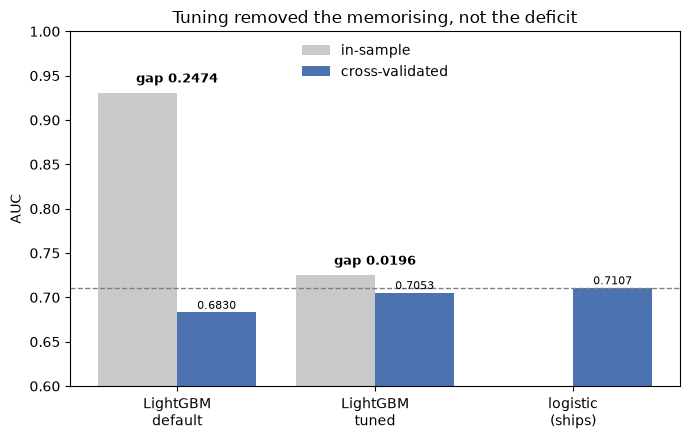

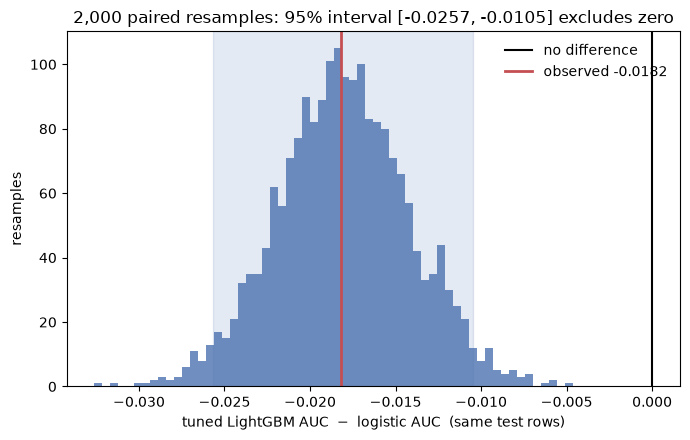

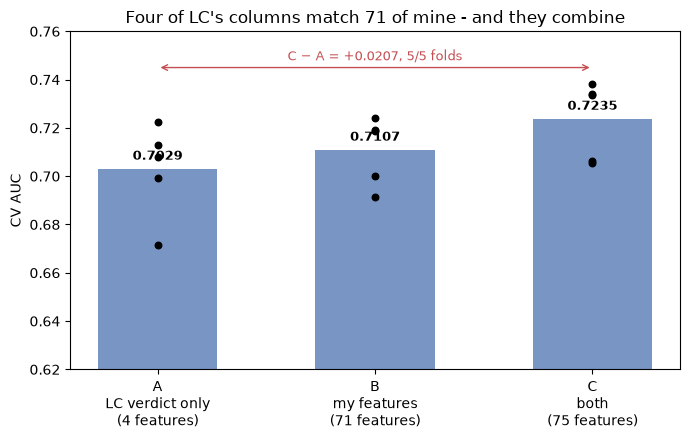

saved 3 figures to ../figures/


In [15]:
# ============ CELL 27: step 8 - the three figures =======================
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

Path("../figures").mkdir(exist_ok=True)

# recorded results from the search (cells 9-13 predate the kernel restart)
TUNED_CV   = 0.7053
DEFAULT_CV = scores_lgb.mean()
LOGREG_CV  = scores_logreg.mean()

# in-sample is cheap to recompute - lgbm_tuned is fitted and in memory
TUNED_IN   = roc_auc_score(y_train_inner,
                           lgbm_tuned.predict_proba(X_train_inner)[:, 1])
DEFAULT_IN = auc_in_sample


# ---- figure 1: the overfit gap, before and after tuning ---------------
fig, ax = plt.subplots(figsize=(7, 4.5))

labels = ["LightGBM\ndefault", "LightGBM\ntuned", "logistic\n(ships)"]
insamp = [DEFAULT_IN, TUNED_IN, np.nan]
cv     = [DEFAULT_CV, TUNED_CV, LOGREG_CV]
x      = np.arange(3)

ax.bar(x - 0.2, insamp, 0.4, label="in-sample", color="#c9c9c9")
ax.bar(x + 0.2, cv,     0.4, label="cross-validated", color="#4c72b0")

for i, (a, b) in enumerate(zip(insamp, cv)):
    if not np.isnan(a):
        ax.annotate(f"gap {a - b:.4f}", (i, a + 0.012),
                    ha="center", fontsize=9, weight="bold")
    ax.annotate(f"{b:.4f}", (i + 0.2, b + 0.004), ha="center", fontsize=8)

ax.axhline(LOGREG_CV, ls="--", lw=1, color="grey")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("AUC"); ax.set_ylim(0.6, 1.0)
ax.set_title("Tuning removed the memorising, not the deficit")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../figures/slice06_overfit_gap.png", dpi=150)
plt.show()


# ---- figure 2: the paired bootstrap -----------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))

d      = boot["auc_diff"]
lo, hi = np.percentile(d, [2.5, 97.5])
point  = roc_auc_score(y_test, p_lgb_test) - roc_auc_score(y_test, p_log_test)

ax.hist(d, bins=60, color="#4c72b0", alpha=0.8)
ax.axvspan(lo, hi, color="#4c72b0", alpha=0.15)
ax.axvline(0,     color="black", lw=1.5, label="no difference")
ax.axvline(point, color="#c44e52", lw=2,
           label=f"observed {point:+.4f}")

ax.set_xlabel("tuned LightGBM AUC  −  logistic AUC  (same test rows)")
ax.set_ylabel("resamples")
ax.set_title(f"2,000 paired resamples: 95% interval "
             f"[{lo:+.4f}, {hi:+.4f}] excludes zero")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../figures/slice06_paired_bootstrap.png", dpi=150)
plt.show()


# ---- figure 3: the verdict ladder -------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))

sets = [("A\nLC verdict only\n(4 features)",  scores_A),
        ("B\nmy features\n(71 features)",     scores_B),
        ("C\nboth\n(75 features)",            scores_C)]

for i, (name, s) in enumerate(sets):
    ax.bar(i, s.mean(), 0.55, color="#4c72b0", alpha=0.75)
    ax.scatter(np.full(len(s), i), s, color="black", zorder=3, s=22)
    ax.annotate(f"{s.mean():.4f}", (i, s.mean() + 0.004),
                ha="center", fontsize=9, weight="bold")

ax.set_xticks(range(3)); ax.set_xticklabels([n for n, _ in sets])
ax.set_ylabel("CV AUC"); ax.set_ylim(0.62, 0.76)
ax.set_title("Four of LC's columns match 71 of mine - and they combine")
ax.annotate("", xy=(2, 0.745), xytext=(0, 0.745),
            arrowprops=dict(arrowstyle="<->", color="#c44e52"))
ax.annotate(f"C − A = +{(scores_C - scores_A).mean():.4f}, 5/5 folds",
            (1, 0.748), ha="center", color="#c44e52", fontsize=9)
fig.tight_layout()
fig.savefig("../figures/slice06_verdict_ladder.png", dpi=150)
plt.show()

print("saved 3 figures to ../figures/")